# Problem Set 2

**Machine Learning for Public Policy**

Jay Ballesteros

October X, 2026

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import statsmodels .api as sm
import statsmodels.formula.api as smf

In [2]:
auto = pd.read_csv("/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/machine_learning/pset_2/data/Data-Auto.csv")
default = pd.read_csv("/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/machine_learning/pset_2/data/Data-Default.csv")

# Q1

**Differences between LDA and QDA**

**(a)  If the Bayes decision boundary is linear, do we expect LDA or QDA to perform better on the training set? On the test set? Briefly explain.**

If the Bayes decision boundary is linear, QDA will generally perform better on the training set because it is more flexible. On the test set, LDA will generally perform better because its lower variance makes it less prone to overfitting, and its linear decision boundary matches the true Bayes boundary.

**(b) If the Bayes decision boundary is non-linear, do we expect LDA or QDA to perform better on the training set? On the test set? Briefly explain**

QDA will generally perform better on the training set because it is more flexible. It will also generally perform better on the test set if its more flexible decision boundary better approximates the true Bayes boundary. However, QDA may overfit when the training sample is small because it has higher variance than LDA.

**(c) In general, as the sample size n increases, do we expect the test prediction accuracy of QDA relative to LDA to improve, decline, or be unchanged? Why?**

To improve! As the sample size increases, QDA's variance decreases, allowing it to better estimate the decision boundary

**(d) True or False: Even if the Bayes decision boundary for a given problem is linear, we will probably achieve a superior test error rate using QDA rather than LDA because QDA is flexible enough to model a linear decision boundary. Justify your answer.**

False. Because QDA, as it estimates more parameters than LDA, has higher variance. When the true boundary is linear, LDA will generally achieve a lower test error because it has lower variance and is less likely to overfit the training data.\

# Q2. 

**Suppose we collect data for a group of students in a statistics class with variables X1 =hours studied, X2 =undergrad GPA, and Y=receive an A. We fit a logistic regression and produce estimated coefficient, β0 =−6, β1 = 0.05, β2 = 1.**


**(a) Predict the probability that a student who studies for 40 hours and has an undergraduate GPA of 3.5 gets an A in the class.**

$$
\begin{aligned}
z &= \beta_0+\beta_1X_1+\beta_2X_2\\
&= -6+0.05(40)+1(3.5)\\
&= -6+2+3.5\\
&= -0.5
\end{aligned}
$$

Following the logistic regression formula:

$$
P(Y=1\mid X)=\frac{e^z}{1+e^z}
$$


$$
\begin{aligned}
P(Y=1\mid X)
&= \frac{e^{-0.5}}{1+e^{-0.5}}\\
&= \frac{0.6065}{1+0.6065}\\
&\approx 0.3775
\end{aligned}
$$

The predicted probability that the student receives an A is approximately 37.75.

**(b) How many hours would the student in the previous question need to study to have a 50% chance of getting an A in the class?**

A probability of 50% occurs when the linear score \(z=0\).

Set the linear score equal to zero and substitute the student's GPA of 3.5:

$$
-6+0.05X_1+1(3.5)=0
$$

Simplify:

$$
\begin{aligned}
-6+0.05X_1+3.5 &= 0\\
0.05X_1-2.5 &= 0\\
0.05X_1 &= 2.5\\
X_1 &= \frac{2.5}{0.05}\\
X_1 &= 50
\end{aligned}
$$

**Answer:** The student would need to study **50 hours** to have a predicted 50% chance of receiving an A.

# Q3 
**Suppose that we wish to predict whether a given stock will issue a dividend this year (“Yes” or “No”) based on X, last year’s percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was X= 10, while the mean for those that didn’t was X= 0. In addition, the variance of X for these two sets of companies was ˆ σ 2 = 36. Finally, 80% of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X= 4 last year.**

Normal density for companies that pay dividends:

$$
\begin{aligned}
f_{\text{Yes}}(4)
&= \frac{1}{6\sqrt{2\pi}}
e^{-\frac{(4-10)^2}{2(36)}}\\
&= \frac{1}{15.0396}e^{-0.5}\\
&\approx 0.0403
\end{aligned}
$$

Normal density for companies that do not pay dividends:

$$
\begin{aligned}
f_{\text{No}}(4)
&= \frac{1}{6\sqrt{2\pi}}
e^{-\frac{(4-0)^2}{2(36)}}\\
&= \frac{1}{15.0396}e^{-2/9}\\
&\approx 0.0532
\end{aligned}
$$

Bayes' theorem:

$$
P(\text{Yes}\mid X=4)=
\frac{f_{\text{Yes}}(4)P(\text{Yes})}
{f_{\text{Yes}}(4)P(\text{Yes})+
f_{\text{No}}(4)P(\text{No})}
$$


$$
\begin{aligned}
P(\text{Yes}\mid X=4)
&= \frac{(0.0403)(0.80)}
{(0.0403)(0.80)+(0.0532)(0.20)}\\
&= \frac{0.03224}{0.04288}\\
&\approx 0.752
\end{aligned}
$$


The predicted probability that a company will issue a dividend, given that its profit last year was 4%, is approximately 75.2%.

# Q4

**In this problem, you will develop a model to predict whether a given car gets high or low gas mileage based on the Auto data set.**

**(a) Create a binary variable, mpg01, that contains a 1 if mpg contains a value above its median, and a 0 if mpg contains a value below its median. You can compute the median using the .median() method of the data frame. Note you may find it helpful to add a column mpg01 to the data frame by assignment.**

In [3]:
median_mpg = auto["mpg"].median()

In [4]:
auto["mpg01"] = (auto["mpg"] > median_mpg).astype(int)

In [5]:
auto["mpg01"].value_counts()

mpg01
0    196
1    196
Name: count, dtype: int64

**(b) Explore the data graphically in order to investigate the association between mpg01 and the other features. Which of the other features seem most likely to be useful in predicting mpg01? Scatterplots and boxplots may be useful tools to answer this question. Describe your findings.**

In [6]:
auto

,Unnamed: 0,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name,mpg01
0,1,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu,0
1,2,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320,0
2,3,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite,0
3,4,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst,0
4,5,17.0,8,302.0,140,3449,10.5,70,1,ford torino,0
...,...,...,...,...,...,...,...,...,...,...,...
387,393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl,1
388,394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup,1
389,395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage,1
390,396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger,1


In [7]:
features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "year"
]

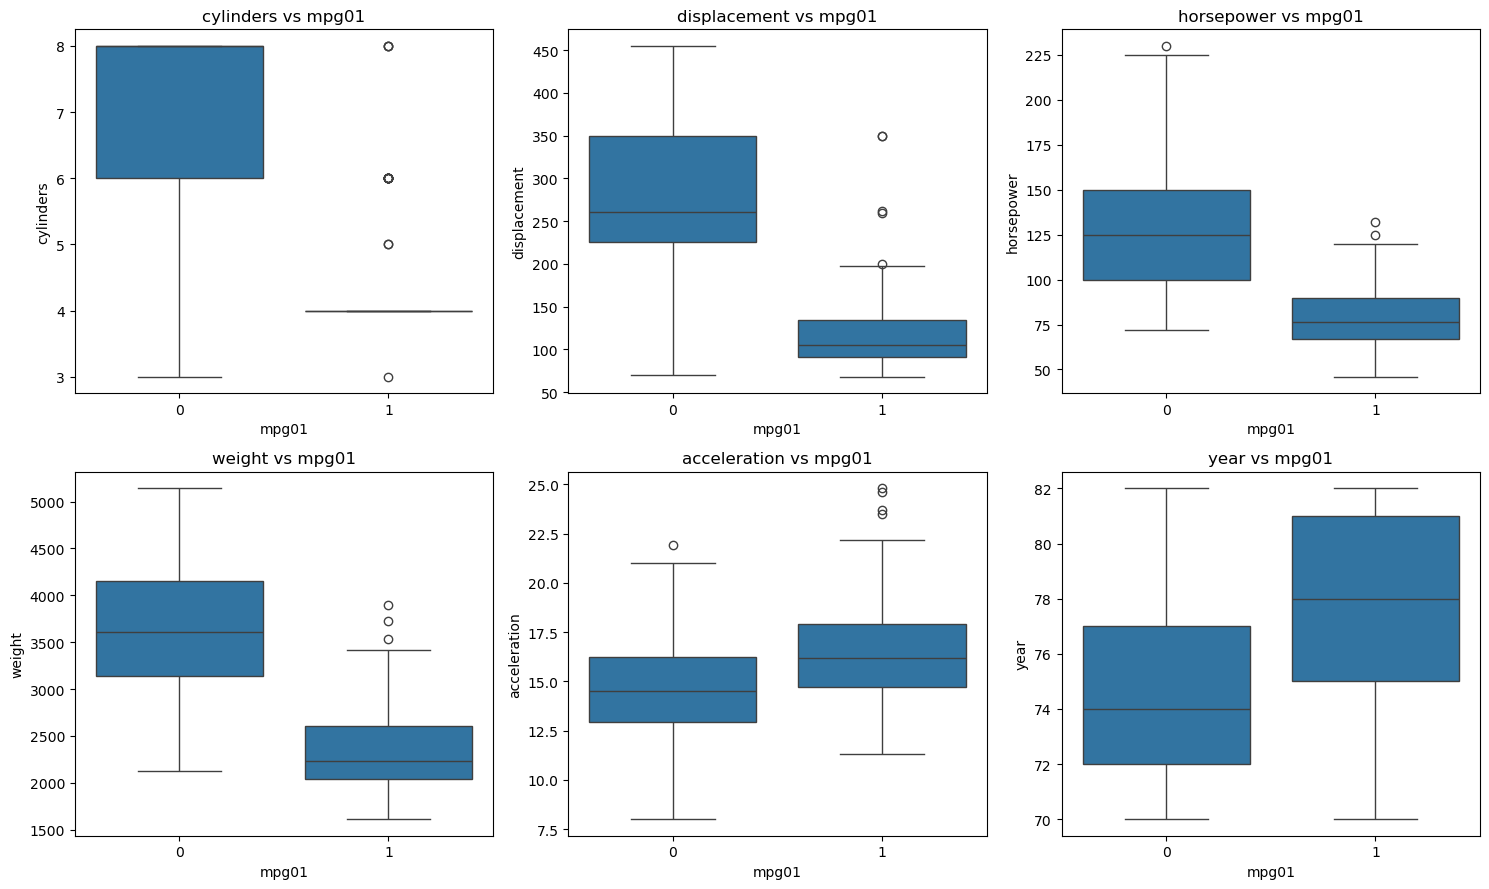

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=auto, x="mpg01", y=feature, ax=ax)
    ax.set_title(f"{feature} vs mpg01")
    ax.set_xlabel("mpg01")

plt.tight_layout()
plt.show()

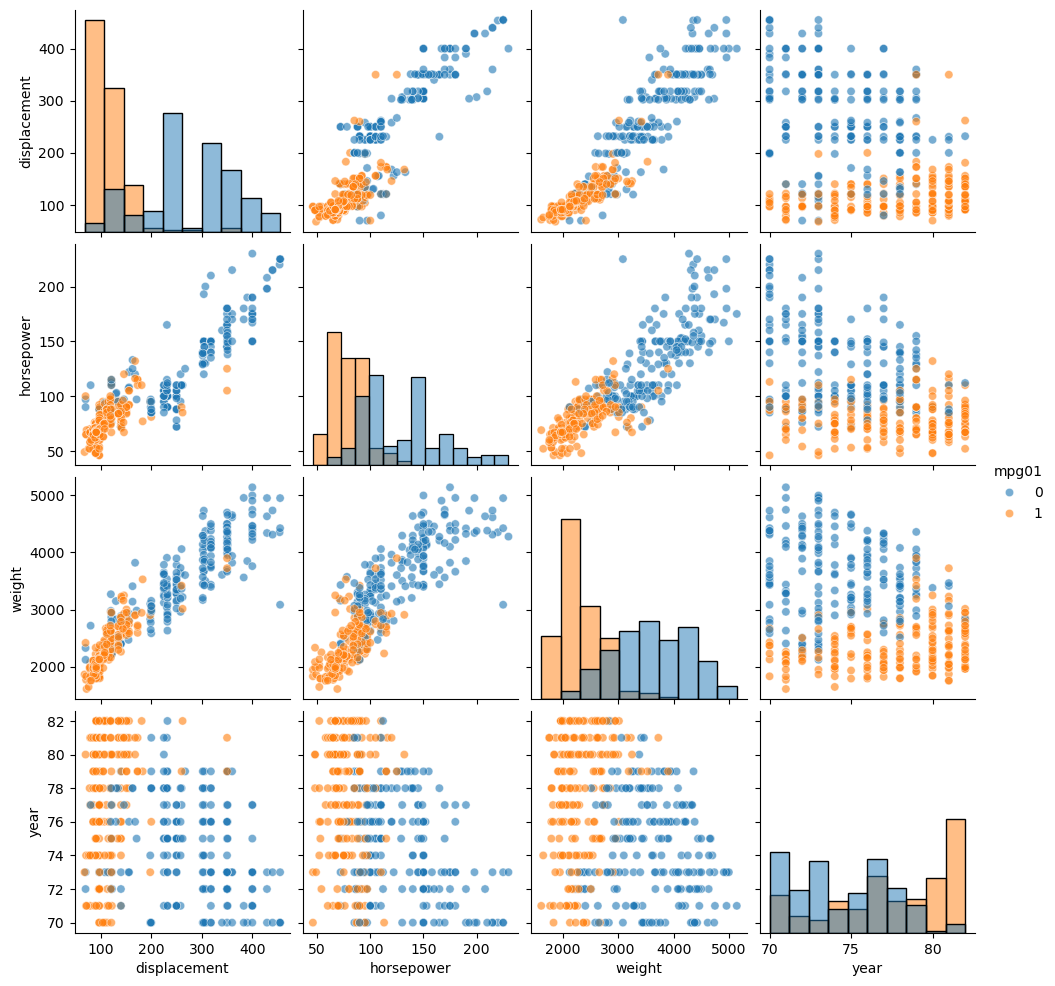

In [9]:
sns.pairplot(
    auto,
    vars=["displacement", "horsepower", "weight", "year"],
    hue="mpg01",
    diag_kind="hist",
    plot_kws={"alpha": 0.6}
)

plt.show()

The median differs sustantially between features based on the categorical variables. But considering the magnitud of median differeces for cylinders, displancement, horsepower and weight, these are more likely to be useful predictors of mpg01.

**(c) Split the data into a training set and a test set. Please use a 50/50 training/test split (50% of the observations in the training set and 50% in the test set). To avoid confusion among partners and facilitate grading, you should set random_state=22 when splitting the data.**

In [10]:
from sklearn.model_selection import train_test_split

# predictors and target
X = auto.drop(columns=["mpg", "mpg01", "name"])
y = auto["mpg01"]

# 50/50
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=22
)

In [11]:
print(X_train.shape)
print(X_test.shape)

(196, 8)
(196, 8)


**(d) Perform LDA on the training data in order to predict mpg01 using the variables that seemed most associated with mpg01 in Question (4b). Calculate and display the confusion matrix when applying your fit to the test set. What is the test error of the model obtained?**

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score

# predictors identified from Q4 (b)
features = ["cylinders", "displacement", "horsepower", "weight", "year"]

X = auto[features]
y = auto["mpg01"]

# 50/50
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=22
)

#lda on the training data
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)

# predict mpg01 for the test set
y_pred = lda.predict(X_test)

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("confusion Matrix:")
print(cm)

# test error
test_error = 1 - accuracy_score(y_test, y_pred)
print(f"test Error: {test_error:.4f}")

confusion Matrix:
[[87 14]
 [ 3 92]]
test Error: 0.0867


**(e) Perform QDA on the training data in order to predict mpg01 using the variables that seemed most associated with mpg01 in Question (4b). Calculate and display the confusion matrix when applying your fit to the test set. What is the test error of the model obtained?**

In [13]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis


# fit QDA on the training data
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

# predict mpg01 on the test set
y_pred_qda = qda.predict(X_test)

# confusion matrix
cm_qda = confusion_matrix(y_test, y_pred_qda)
print("QDA Confusion Matrix:")
print(cm_qda)

# test error
test_error_qda = 1 - accuracy_score(y_test, y_pred_qda)
print(f"QDA test error: {test_error_qda:.4f}")

QDA Confusion Matrix:
[[89 12]
 [ 9 86]]
QDA test error: 0.1071


**(f)  Perform logistic regression on the training data in order to predict mpg01 using the variables that seemed most associated with mpg01 in Question (4b). Calculate and display the confusion matrix when applying your fit to the test set. What is the test error of the model obtained?**

In [14]:
# fit logistic regression on the training data
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# predict mpg01 for the test set
y_pred_log = log_reg.predict(X_test)

# confusion matrix
cm_log = confusion_matrix(y_test, y_pred_log)
print("confusion matrix:")
print(cm_log)

# test error
test_error_log = 1 - accuracy_score(y_test, y_pred_log)
print(f"test error: {test_error_log:.4f}")

confusion matrix:
[[92  9]
 [ 7 88]]
test error: 0.0816


**(g) Perform naive Bayes on the training data in order to predict mpg01 using the variables that seemed most associated with mpg01 in Question (4b). Calculate and display the confusion matrix when applying your fit to the test set. What is the test error of the model obtained?**

In [15]:
from sklearn.naive_bayes import GaussianNB

# fit Naive Bayes on the training data
nb = GaussianNB()
nb.fit(X_train, y_train)

# predict mpg01 on the test set
y_pred_nb = nb.predict(X_test)

# confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)
print("confusion matrix:")
print(cm_nb)

# test error
test_error_nb = 1 - accuracy_score(y_test, y_pred_nb)
print(f"test error: {test_error_nb:.4f}")

confusion matrix:
[[88 13]
 [ 8 87]]
test error: 0.1071


**(h) Which model (LDA, QDA, logit, or naive Bayes) do you prefer? Why should you be concerned about selecting a model in this way?**

I would prefer the logit prefer because it achieved the lowest test error (0.0816). But this is the case because very likely that the bayes boundary is linear.

However,given by the potential of overfitting, a better approach would be to use cross-validation on the training data to select the model and reserve the test set for the final evaluation.

# Q5. 

**In Chapter 4, we used logistic regression to predict the probability of default using income and balance on the Default data set. We will now estimate the test error of this logistic regression model using the validation set approach. Do not forget to set a random seed before beginning your analysis.**

**(a) Fit a logistic regression model that uses income and balance to predict default. Report the parameter estimates from your fit.**

In [16]:
np.random.seed(22)

# predictors and response
X = default[["income", "balance"]]
y = default["default"]

# intercept
X = sm.add_constant(X)

# fit logistic regression
logit_model = sm.Logit(y.map({"No": 0, "Yes": 1}) if y.dtype == "object" else y, X)
result = logit_model.fit()

# parameter estimates
print(result.summary())

# just the coefficients
print("\nParameter estimates:")
print(result.params)

Optimization terminated successfully.
         Current function value: 0.078948
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9997
Method:                           MLE   Df Model:                            2
Date:                Thu, 29 Oct 2026   Pseudo R-squ.:                  0.4594
Time:                        23:26:04   Log-Likelihood:                -789.48
converged:                       True   LL-Null:                       -1460.3
Covariance Type:            nonrobust   LLR p-value:                4.541e-292
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.5405      0.435    -26.544      0.000     -12.393     -10.688
income      2.081e-05   4.99

**(b) Using the validation set approach, estimate the test error of this model. In order to do this, you should perform the following steps:**

i. Split the sample set into a training set and a validation set. In this question, please use a 70/30 training/validation set split. Please set random_state=42 when splitting the data.

ii. Fit a multiple logistic regression model using only the training observations.

iii. Obtain a prediction of default status for each individual in the validation set by computing the posterior probability of default for that individual, and classifying the individual to the default category if the posterior probability is greater than 0.5.

iv. Compute the validation set error, which is the fraction of the observations in the validation set that are misclassified.

In [17]:
# default status to numeric
if y.dtype == "object":
    y = y.map({"No": 0, "Yes": 1})

# 70% training and 30% validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# logistic regression using training data only
X_train_sm = sm.add_constant(X_train)
X_val_sm = sm.add_constant(X_val)

logit_model = sm.Logit(y_train, X_train_sm)
result = logit_model.fit()

# predict posterior probabilities on the validation set
y_prob = result.predict(X_val_sm)

# classify as default if probability > 0.5
y_pred = (y_prob > 0.5).astype(int)

# confusion matrix and validation error
cm = confusion_matrix(y_val, y_pred)
validation_error = (y_pred != y_val).mean()

print(" ")
print("confusion matrix:")
print(" ")
print(cm)
print(" ")
print(f"validation set error: {validation_error:.4f}")
print(f"validation set error (%): {validation_error * 100:.2f}%")

Optimization terminated successfully.
         Current function value: 0.078256
         Iterations 10
 
confusion matrix:
 
[[2896   10]
 [  70   24]]
 
validation set error: 0.0267
validation set error (%): 2.67%


**(c) Repeat the process in Question (5b) three times, using three different splits of the observations into a training set and a validation set. In this question, keep the 70/30 training/validation set split. Please set random_states of 2, 6, and 9 to obtain the three different splits of the observations. Comment on the results obtained.**

In [18]:
# repeat the validation-set approach for three random states
random_states = [2, 6, 9]
results = []

for seed in random_states:
    # split the data 70/30
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.3, random_state=seed
    )

    # fit logistic regression on training data
    X_train_sm = sm.add_constant(X_train)
    X_val_sm = sm.add_constant(X_val)

    model = sm.Logit(y_train, X_train_sm).fit(disp=0)

    # predict probabilities and classify using threshold 0.5
    probabilities = model.predict(X_val_sm)
    y_pred = (probabilities > 0.5).astype(int)

    # calculate confusion matrix and validation error
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
    error = (y_pred != y_val).mean()

    results.append({
        "Random State": seed,
        "Validation Error": error,
        "Validation Error (%)": error * 100
    })

    print(f"\nRandom state: {seed}")
    print("Confusion matrix:")
    print(cm)
    print(f"Validation error: {error:.4f} ({error * 100:.2f}%)")

# compare validation errors
results_df = pd.DataFrame(results)
print("\ncomparison of validation errors:")
display(results_df)


Random state: 2
Confusion matrix:
[[2906   18]
 [  53   23]]
Validation error: 0.0237 (2.37%)

Random state: 6
Confusion matrix:
[[2896   10]
 [  64   30]]
Validation error: 0.0247 (2.47%)

Random state: 9
Confusion matrix:
[[2900    9]
 [  56   35]]
Validation error: 0.0217 (2.17%)

comparison of validation errors:


,Random State,Validation Error,Validation Error (%)
0,2,0.023667,2.366667
1,6,0.024667,2.466667
2,9,0.021667,2.166667


The validation errors obtained using random states 2, 6, and 9 are 0.0236, 0.0246, 0.0216. The results show that the estimated test error varies across different training/validation splits. This variation occurs because the model is fitted on different training observations and evaluated on different validation observations. 

**(d) Now consider a logistic regression model that predicts the probability of default using income, balance, and a dummy variable for student. Estimate the test error for this model using the validation set approach. Please use a 70/30 training/validation set split, and set random_state=42 when splitting the data. Comment on whether or not including a dummy variable for student leads to a reduction in the test error rate.**

In [19]:
# define predictors and response
X = default[["income", "balance", "student"]].copy()
y = default["default"].copy()

# categorical variables to numeric
if y.dtype == "object":
    y = y.map({"No": 0, "Yes": 1})

# encode student as a dummy variable
if X["student"].dtype == "object":
    X["student"] = X["student"].map({"No": 0, "Yes": 1})

# split into training and validation sets (70/30)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# fit logistic regression using training data only
X_train_sm = sm.add_constant(X_train)
X_val_sm = sm.add_constant(X_val)

model_student = sm.Logit(y_train, X_train_sm).fit()

# predict probabilities and classify using threshold 0.5
y_prob = model_student.predict(X_val_sm)
y_pred = (y_prob > 0.5).astype(int)

# calculate confusion matrix and validation error
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
validation_error_student = (y_pred != y_val).mean()

print("confusion matrix:")
print(cm)
print(f"validation error: {validation_error_student:.4f}")
print(f"validation error (%): {validation_error_student * 100:.2f}%")

Optimization terminated successfully.
         Current function value: 0.078031
         Iterations 10
confusion matrix:
[[2895   11]
 [  69   25]]
validation error: 0.0267
validation error (%): 2.67%


In [20]:
print(f"model without student: {validation_error:.4f}")
print(f"model with student:    {validation_error_student:.4f}")

if validation_error_student < validation_error:
    print("including student reduces the validation error")
elif validation_error_student > validation_error:
    print("including student increases the validation error")
else:
    print("both models have the same validation error")

model without student: 0.0267
model with student:    0.0267
both models have the same validation error


The validation error for the model using income and balance was 2.6%.
After including student as a dummy variable, the validation error was the same!